
Large-Scale Business Intelligence

Context: A global e-commerce corporation is optimizing its regional checkout architectures. The data science team extracted a dataset containing 100,000 transaction records to evaluate how website formatting and internal operations affect financial performance.

The dataset contains three primary variables across 100,000 rows:
• Checkout_Design: The layout shown to the user (Design_A, Design_B, or Design_C).

• PM_Framework: The software deployment framework managing the system backend (Scrum or Kanban).

• Transaction_Value_USD: The total dollar amount spent during the session.

# Business Statement :

 Using a significance level of α = 0.05, determine if the mean Transaction_Value_USD differs significantly based solely on the website layout variant.

H0: Mean Transaction Value_USd Do not Differs Significantly solely on the website layout variant


UDC = UDA = UDB

H1 :Atlest one checkout_design average Transaction_value_USD differs


UDC!=UDA or UDC!=UDB


TEST : ONE-WAY ANOVA

In [4]:
import numpy as np
import pandas as pd


In [5]:
df=pd.read_csv('/content/anova_business_large_dataset.csv')

In [6]:
df.head()

,Row_ID,Checkout_Design,PM_Framework,Transaction_Value_USD
0,1,Design_C,Kanban,51.65
1,2,Design_A,Scrum,28.79
2,3,Design_C,Kanban,56.49
3,4,Design_C,Scrum,82.92
4,5,Design_A,Scrum,53.46


<Axes: xlabel='Checkout_Design', ylabel='Transaction_Value_USD'>

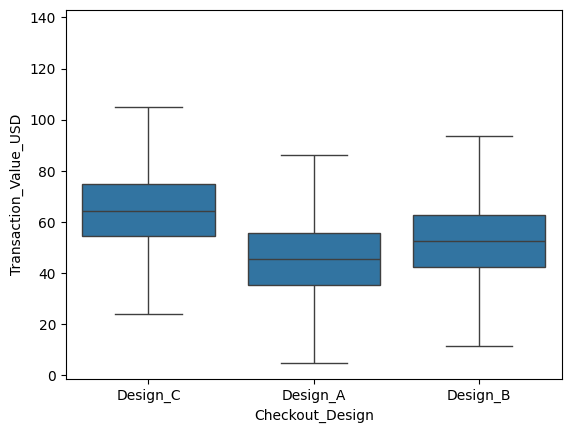

In [7]:
import seaborn as sns
y=df['Transaction_Value_USD']
x=df.Checkout_Design.value_counts()
sns.boxplot(data=df,x='Checkout_Design',y='Transaction_Value_USD',fliersize=False)

In [8]:
from statsmodels.formula.api import ols

from statsmodels.stats.api import anova_lm

mod=ols('Transaction_Value_USD ~ Checkout_Design',data=df).fit()
anova=anova_lm(mod,typ=2)

In [9]:
anova

,sum_sq,df,F,PR(>F)
Checkout_Design,6.160631e+06,2.0,13434.924833,0.0
Residual,2.292699e+07,99997.0,NaN,NaN


In [10]:
p_value=anova['PR(>F)'][0]

/tmp/ipykernel_1044/3242222112.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_value=anova['PR(>F)'][0]


In [11]:
if(p_value<0.05):
  print("Reject Null Hypothesis")
else:
  print("Fail to Reject the Null Hypothesis")

Reject Null Hypothesis


# Conclusion :

We have strong evidence that website layout directly impacts how much money customers spend. The differences in revenue across the designs are not due to random chance.

Using a significance level of α = 0.05, evaluate the simultaneous structural impacts of the frontend and backend teams. Calculate and report the F-statistics and p-values for:

1. Main Effect of Checkout Design: Does frontend presentation impact transaction revenue at scale?

2. Main Effect of PM Framework: Does backend deployment methodology independently impact order processing values?

3. Interaction Effect (Design times Framework): Does the operational efficiency of a specific engineering framework change depending on which layout variant it serves to customers?



H0:avg Transation(Design) and Transasction(Framework) are not Associated


H1:Transaction(Design) and Transaction(Framework) are Associated

Test : MULTIWAY ANOVA

In [12]:
df.head()

,Row_ID,Checkout_Design,PM_Framework,Transaction_Value_USD
0,1,Design_C,Kanban,51.65
1,2,Design_A,Scrum,28.79
2,3,Design_C,Kanban,56.49
3,4,Design_C,Scrum,82.92
4,5,Design_A,Scrum,53.46


<Axes: xlabel='Checkout_Design', ylabel='Transaction_Value_USD'>

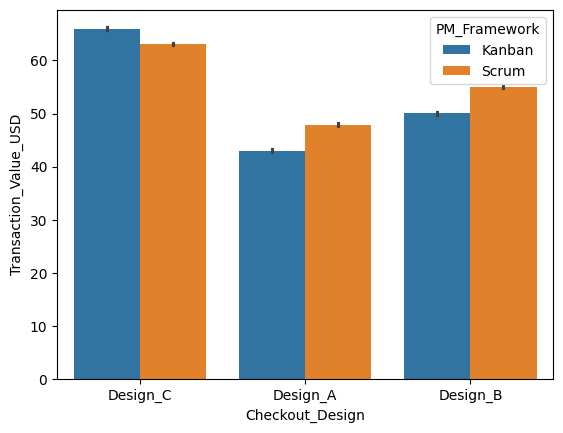

In [16]:
import seaborn as sns

sns.barplot(data=df,x='Checkout_Design',y='Transaction_Value_USD',hue='PM_Framework')

In [14]:
from statsmodels.formula.api import ols
import statsmodels.api as sm
mod=ols('Transaction_Value_USD ~ C(Checkout_Design) * C(PM_Framework)',data=df).fit()
anova=sm.stats.anova_lm(mod,typ=2)

anova

,sum_sq,df,F,PR(>F)
C(Checkout_Design),6.161634e+06,2.0,13726.293769,0.000000e+00
C(PM_Framework),1.407293e+05,1.0,627.006249,5.975662e-138
C(Checkout_Design):C(PM_Framework),3.429646e+05,2.0,764.023457,0.000000e+00
Residual,2.244329e+07,99994.0,NaN,NaN


# 1. Main Effect of Checkout Design: Does frontend presentation impact transaction revenue at scale?

p_value<0.05

Therefore Reject the null hypothesis.

Frontend presentation does significantly impact transaction revenue at scale. The extremely high F-statistic indicates that checkout design is the strongest individual driver of revenue variation in this model.




# 2. Main Effect of PM Framework: Does backend deployment methodology independently impact order processing values?

Reject the null hypothesis.

The backend deployment methodology (PM Framework) independently impacts order
processing values to a highly significant degree.





# 3. Interaction Effect (Design times Framework): Does the operational efficiency of a specific engineering framework change depending on which layout variant it serves to customers?


 Reject the null hypothesis.

 There is a highly significant interaction effect. This means the operational efficiency and impact of a specific PM framework on revenue changes depending on which checkout layout variant is being served to customers.


